In [1]:
# plots will be shown inline 
%matplotlib inline 
import matplotlib.pyplot as plt

import numpy
from numpy import sqrt,floor

import numpy as np
import pandas as pd
import random
import math

# libreria locale
import my_lib_santanastasio as my
##NOTA IMPORTANTE: se cambi qualcosa in my_lib_santanastasio 
# devi fare Kernel --> Restart prima di rigirare il codice
# altrimenti i cambiamenti non saranno applicati.

from scipy import stats
import scipy.integrate as integrate
from scipy.optimize import minimize

# set global random seed
random_Gseed = 1112
np.random.seed(random_Gseed)

# Dati e modello di fit

In [2]:
# modello e valori di x
m_true = 4
c_true = 2
sigma_y_true = 0.1

x = np.arange(0.5,3,0.1) #default
ux = np.repeat(0.0,len(x))

y_true = m_true*x + c_true
uy_true = np.repeat(sigma_y_true,len(x))
y = np.random.normal(y_true,uy_true)
uy = uy_true*1

print (x)
print (y_true)
print (uy_true)
print (y.round(2))
print (uy)
print (ux)

[0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8 1.9 2.  2.1 2.2
 2.3 2.4 2.5 2.6 2.7 2.8 2.9]
[ 4.   4.4  4.8  5.2  5.6  6.   6.4  6.8  7.2  7.6  8.   8.4  8.8  9.2
  9.6 10.  10.4 10.8 11.2 11.6 12.  12.4 12.8 13.2 13.6]
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
[ 4.09  4.37  4.69  5.12  5.63  5.9   6.41  6.84  7.19  7.55  7.94  8.5
  8.65  9.3   9.49  9.95 10.5  10.84 11.3  11.61 11.83 12.28 12.73 13.25
 13.65]
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]


# Fit lineare con formule

m         =  4.0046
sigma(m)  =  0.0277
c         =  1.9771
sigma(c)  =  0.0512
cov(m, c) =  -0.0013
rho(m, c) =  -0.9206


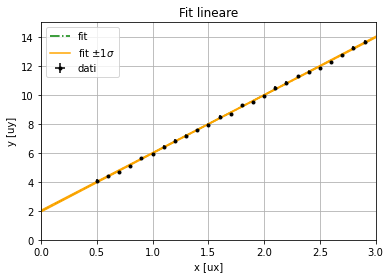

In [3]:
#prima iterazione (assumo sigma x=0)
m0, sm0, c0, sc0, cov0, rho0 = my.lin_fit(x, y, uy, "x [ux]", "y [uy]", 0, 3, 0, 15, plot=True, setrange=True)

[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1
 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
m         =  4.0046
sigma(m)  =  0.0277
c         =  1.9771
sigma(c)  =  0.0512
cov(m, c) =  -0.0013
rho(m, c) =  -0.9206


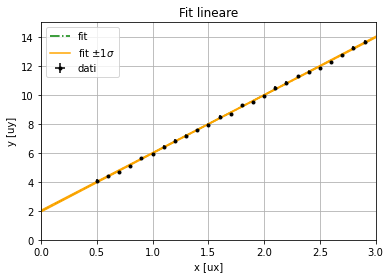

In [4]:
# nuove y (propagando incertezza delle x sulle y)
uy_new = np.sqrt(uy**2+(m0*ux)**2)
print (uy_new)
# fit finale
m, sm, c, sc, cov, rho = my.lin_fit(x, y, uy_new, "x [ux]", "y [uy]", 0, 3, 0, 15, plot=True, setrange=True)

# Fit attraverso integrazione della posterior

In [5]:
# Assumo prior vaga (costante) --> posterior ~ likelihood (a meno della normalizzazione)
def posterior(M,C,Y,X,SigmaY):    
    Yexp = M * X + C # modello di fit
    #print (Yexp)
    return np.prod( stats.norm.pdf(Y, Yexp, SigmaY) )

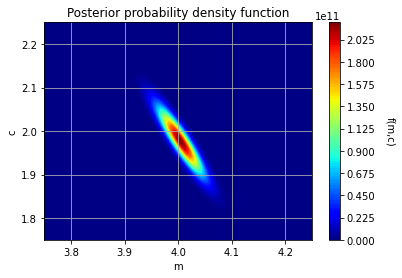

In [9]:
## Disegnare la posterior
from matplotlib import cm
m_values = np.linspace(3.75, 4.25, 100)
c_values = np.linspace(1.75, 2.25, 100)
m_mesh, c_mesh = np.meshgrid(m_values, c_values)

posterior_values = np.zeros(len(m_values)*len(c_values))
idx = 0
for mval, cval in np.nditer([m_mesh,c_mesh]):
    posterior_values[idx]=posterior(mval,cval,y,x,uy_new) 
    idx = idx + 1
posterior_mesh = posterior_values.reshape((len(c_values), len(m_values)))

fig = plt.figure()
ax1 = plt.contourf(m_mesh, c_mesh, posterior_mesh, cmap=cm.jet, levels=100)
cbar = plt.colorbar(ax1)
cbar.set_label('f(m,c)', rotation=270, labelpad=20)
plt.xlabel("m")
plt.ylabel("c")
plt.grid()
plt.title("Posterior probability density function")
plt.show()

Text(0.5, 0.92, 'Posterior probability density function')

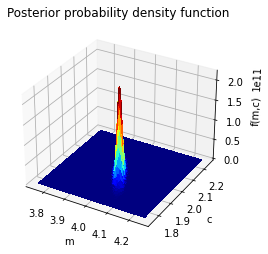

In [10]:
from matplotlib import cm
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
surf = ax.plot_surface(m_mesh, c_mesh, posterior_mesh, cmap=cm.jet,
                       linewidth=0, antialiased=False)

ax.set_xlabel('m')
ax.set_ylabel('c')
ax.set_zlabel('f(m,c)')
plt.title("Posterior probability density function")

In [11]:
# Range delle variabili su cui fare inferenza

#it works with uy=0.1, ux=0
range_m = (3.75, 4.25)
range_c = (1.75, 2.25)

#range_m = (0,10)
#range_c = (0,10)

# Integrale di normalizzazione della posterior
normalization, integral_error_norm = integrate.nquad(posterior, 
                                                    [range_m, #m
                                                     range_c  #c
                                                    ],
                                                    args=(y,x,uy_new)
                                                    )
print (normalization, integral_error_norm)

# Posterior normalizzata (PDF)
def posterior_norm(M,C,Y,X,SigmaY):    
    return posterior(M,C,Y,X,SigmaY) / normalization

# L'argomento dell'integrale del valore atteso di c^k 
def arg_E_c_k(M,C,k,Y,X,SigmaY):
    return np.power(C,k) * posterior_norm(M,C,Y,X,SigmaY)

# L'argomento dell'integrale del valore atteso di m^k 
def arg_E_m_k(M,C,k,Y,X,SigmaY):
    return np.power(M,k) * posterior_norm(M,C,Y,X,SigmaY)

# L'argomento dell'integrale del valore atteso di m*c
def arg_E_mc(M,C,Y,X,SigmaY):
    return M * C * posterior_norm(M,C,Y,X,SigmaY)

769813647.1306431 29.658546460418435


In [12]:
E_c, error_int_E_c = integrate.nquad(arg_E_c_k, 
                                    [range_m, #m
                                    range_c  #c
                                    ],
                                    args=(1,y,x,uy_new)#k=1
                                    )
E_c2, error_int_E_c2 = integrate.nquad(arg_E_c_k, 
                                        [range_m, #m
                                        range_c  #c
                                        ],
                                        args=(2,y,x,uy_new)#k=2
                                        )
Var_c = E_c2 - E_c**2
Sigma_c = math.sqrt(Var_c)

In [13]:
E_m, error_int_E_m = integrate.nquad(arg_E_m_k, 
                                    [range_m, #m
                                    range_c  #c
                                    ],
                                    args=(1,y,x,uy_new)#k=1
                                    )
E_m2, error_int_E_m2 = integrate.nquad(arg_E_m_k, 
                                        [range_m, #m
                                        range_c  #c
                                        ],
                                        args=(2,y,x,uy_new)#k=2
                                        )
Var_m = E_m2 - E_m**2
Sigma_m = math.sqrt(Var_m)

In [14]:
E_mc, error_int_E_mc = integrate.nquad(arg_E_mc, 
                                       [range_m, #m
                                        range_c  #c
                                        ],
                                        args=(y,x,uy_new)
                                        )
Cov_mc = E_mc - E_m*E_c
Rho_mc = Cov_mc / (Sigma_m*Sigma_c)

In [15]:
my.PrintResult("m_fit",E_m,Sigma_m,20,"[y/x]")
my.PrintResult("c_fit",E_c,Sigma_c,20,"[y]")
print ("Cov[m,c] fit", Cov_mc)
print ("Rho[m,c] fit", Rho_mc)
print("\nda confrontare con i risultati ottenuti tramite le formule del fit lineare:\n")
my.PrintResult("m_formula",m,sm,20,"[y/x]")
my.PrintResult("c_formula",c,sc,20,"[y]")
print ("Cov[m,c] formula", cov)
print ("Rho[m,c] formula", rho)
print("\nsi lasciano appositamente molte cifre significative al solo scopo di confronto")

m_fit = (4.004630910306492 +/- 0.02773387716936505 ) [y/x] [0.69%]
c_fit = (1.9771261034310252 +/- 0.05121351517982596 ) [y] [2.59%]
Cov[m,c] fit -0.0013075662853427872
Rho[m,c] fit -0.9205948487906009

da confrontare con i risultati ottenuti tramite le formule del fit lineare:

m_formula = (4.004631449795384 +/- 0.027735009811261434 ) [y/x] [0.69%]
c_formula = (1.9771250212797788 +/- 0.051215983082207046 ) [y] [2.59%]
Cov[m,c] formula -0.0013076923076923053
Rho[m,c] formula -0.9206016138255998

si lasciano appositamente molte cifre significative al solo scopo di confronto


# Distribuzione marginale di c

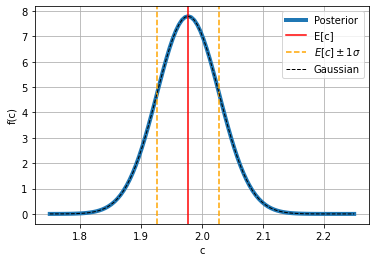

In [16]:
def posterior_1(M,C,Y,X,SigmaY):    
    Yexp = M * X + C # modello di fit
    #print (Yexp)
    return np.prod( stats.norm.pdf(Y, Yexp, SigmaY) )

def posterior_1_norm(M,C,Y,X,SigmaY):    
    return posterior_1(M,C,Y,X,SigmaY) / normalization

posterior_norm_c = lambda C: integrate.nquad(posterior_1_norm, [range_m], args=(C,y,x,uy_new))[0]
posterior_norm_c_vfunc = np.vectorize(posterior_norm_c)

posterior_norm_c_values = posterior_norm_c_vfunc(c_values)

plt.plot(c_values,posterior_norm_c_values,label='Posterior',linewidth=4)
plt.xlabel("c")
plt.ylabel("f(c)")
plt.axvline(x = E_c, color = 'r', linestyle='-',label='E[c]')
plt.axvline(x = E_c+Sigma_c, color = 'orange', linestyle='--', label='$E[c] \pm 1\sigma$')
plt.axvline(x = E_c-Sigma_c, color = 'orange', linestyle='--')
plt.plot(c_values, stats.norm.pdf(c_values,E_c,Sigma_c), linewidth=1, color='black',linestyle='--',label='Gaussian')
plt.legend()
plt.grid()

# Distribuzione marginale di m

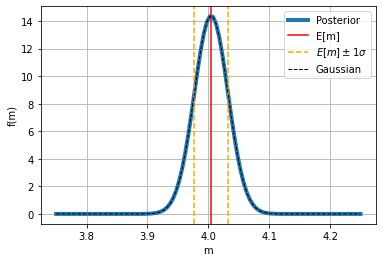

In [17]:
def posterior_2(C,M,Y,X,SigmaY):    
    Yexp = M * X + C # modello di fit
    #print (Yexp)
    return np.prod( stats.norm.pdf(Y, Yexp, SigmaY) )

def posterior_2_norm(C,M,Y,X,SigmaY):    
    return posterior_2(C,M,Y,X,SigmaY) / normalization

posterior_norm_m = lambda M: integrate.nquad(posterior_2_norm, [range_c], args=(M,y,x,uy_new))[0]
posterior_norm_m_vfunc = np.vectorize(posterior_norm_m)

posterior_norm_m_values = posterior_norm_m_vfunc(m_values)

plt.plot(m_values,posterior_norm_m_values,label='Posterior',linewidth=4)
plt.xlabel("m")
plt.ylabel("f(m)")
plt.axvline(x = E_m, color = 'r', linestyle='-',label='E[m]')
plt.axvline(x = E_m+Sigma_m, color = 'orange', linestyle='--', label='$E[m] \pm 1\sigma$')
plt.axvline(x = E_m-Sigma_m, color = 'orange', linestyle='--')
plt.plot(m_values, stats.norm.pdf(m_values,E_m,Sigma_m), linewidth=1, color='black',linestyle='--',label='Gaussian')
plt.legend()
plt.grid()

